In [1]:
from pathlib import Path
import re
import json 
import sys
import os

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib notebook
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

module_path = os.path.abspath(os.path.join('../'))
if module_path not in sys.path:
    sys.path.append(module_path)


In [2]:
font_size = 18
matplotlib.rcParams['font.size'] = font_size
matplotlib.rcParams["font.weight"] = "bold"
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['axes.labelsize'] = font_size
matplotlib.rcParams['axes.titlesize'] = 28
matplotlib.rcParams['legend.fontsize'] = font_size
matplotlib.rcParams['xtick.labelsize'] = font_size
matplotlib.rcParams['ytick.labelsize'] = font_size
#matplotlib.rcParams['text.latex.preamble']=r'\usepackage{amsmath} \DeclareMathOperator{\F}{F} \DeclareMathOperator{\GMF}{GMF} \DeclareMathOperator{\MLP}{MLP}'

In [3]:
def read_tb_file(tb_file):
    ea = event_accumulator.EventAccumulator(str(tb_file),
                                            size_guidance={ 
                                                event_accumulator.COMPRESSED_HISTOGRAMS: 0,
                                                event_accumulator.IMAGES: 0,
                                                event_accumulator.AUDIO: 0,
                                                event_accumulator.SCALARS: 0,
                                                event_accumulator.HISTOGRAMS: 0,})
    ea.Reload()
    return ea

def create_df_from_ea(ea, tag):
    steps = [x.step for x in ea.Scalars(tag)]
    values = [x.value for x in ea.Scalars(tag)]
    t0 = ea.Scalars(tag)[0].wall_time
    time = [x.wall_time-t0 for x in ea.Scalars(tag)]

    df = pd.DataFrame({"Time": time, "Step": steps, "Value": values})
    return df

def get_hparams_from_ea(ea):
    hparams_string = ea.Tensors('hyperparameters/text_summary')[0][2].string_val[0].decode()
    hparams_l = hparams_string.replace('|\n|',',').replace('|',':').replace(':param:value,-:-,','').split(',')
    keys = [i.split(':')[0] for i in hparams_l if len(i.split(':'))>1]
    values = [i.split(':')[1] for i in hparams_l if len(i.split(':'))>1]
        
    d = {k:v for k,v in zip(keys,values)}
    
    return d

def create_mu_std_df_from_ea(ea_dict, tag, filter_best=False, n_best=5):
    min_len = 1e6
    
    df_list = []
    for name, ea in ea_dict.items():
        df = create_df_from_ea(ea, tag)
        if len(df) < min_len:
            min_len = len(df)
        df_list.append(df)

    return create_mu_std_df(df_list, filter_best, n_best)

def create_mu_std_df(df_list, filter_best=False, n_best=5):
    print(df_list)
    val_list = []
    for df in df_list:
        val_list.append(df["Value"])
    val_list = np.array(val_list)
    
    means = np.mean(val_list, axis=-1)
    idx = np.argsort(-means)
    if filter_best:
        vals = val_list[idx[:n_best]]
    else:
        vals = val_list
    x_axis = df_list[0]["Step"][:min_len]
    
    mu = np.mean(vals, axis=0)
    median = np.median(vals, axis=0)
    std = np.std(vals, axis=0)
    q1 = np.quantile(vals, 0.25, axis=0)
    q3 = np.quantile(vals, 0.75, axis=0)
    best = val_list[idx[0]]
    return pd.DataFrame({"Step": x_axis, "mu": mu, "std": std, "best": best, "median": median, "q1": q1, "q3": q3})

def load_dirs(tasks_dir, tags, save_path=None):
    # init dicts
    df_dict = {}
    for tag in tags:
        df_dict[tag] = {}
        
    for task_dir in tqdm(tasks_dir.iterdir()):        
        ea_dict = {}

        if len(list((task_dir).iterdir())) > 0:
            try:
                ea_dict[task_dir] = read_tb_file(task_dir)
            except:
                print(f"WARNING: No data in {run_dir}. Skipped.")
                continue

        if ea_dict:
            for tag in tags:
                df_dict[tag][task_dir.name] = create_mu_std_df(
                    ea_dict, tag, filter_best=True, n_best=5).copy()
    
    if save_path:
        with open(save_path, 'wb') as handle:
            pkl.dump(df_dict, handle, protocol=pkl.HIGHEST_PROTOCOL)
    return df_dict

def plot_mu_std(x_axis, mu, q1=None, q3=None, std=None, fig=None, title=None, label='', yuplim=None, 
                ydownlim=None, interpolate=False, max_num_tasks=None):
    if fig is None:
        fig = plt.figure(figsize=[12,10])
        
    if interpolate:
        from scipy.interpolate import make_interp_spline, BSpline
        std = std[::2]
        new_size = std.shape[0]
        
        xnew = np.linspace(x_axis.min(), x_axis.max(), new_size)
        spl = make_interp_spline(x_axis, mu, k=3)  # type: BSpline
        power_smooth = spl(xnew)
        
        x_axis = xnew
        power_smooth = np.clip(power_smooth, np.min(mu), np.max(mu))
        mu = power_smooth

    if std is not None:
        uperror = mu+std
        downerror = mu-std
        
        uperror = np.clip(uperror, np.min(mu), np.max(mu))
        downerror = np.clip(downerror, np.min(mu), np.max(mu))
    else:
        uperror = q3
        downerror = q1    
    
    if yuplim is not None:
        uperror = np.where(uperror > yuplim, yuplim, uperror)
    if ydownlim is not None:
        downerror = np.where(downerror < ydownlim, ydownlim, downerror)
    plt.plot(x_axis, mu, label=label)
    plt.fill_between(x_axis, downerror, uperror, alpha=.1)
    plt.xlabel("Timesteps", fontsize=16)
    plt.yticks(fontsize=16)
    plt.xticks(fontsize=16)
    
    if title is not None:
        plt.title(title)

#     plt.ticklabel_format(axis="x", style="sci", scilimits=(0,0))
    if max_num_tasks:
        plt.yticks(np.arange(max_num_tasks+1), 
                   ["{0:1.1f}\%".format(100.0 * i/max_num_tasks) for i in np.arange(max_num_tasks+1)])
#     plt.legend(loc="lower right")
#     plt.legend(loc="upper left")
    
    return fig

def create_mean_std_plot(ea_dict, tag,  title, smoothing=3.0, savefig_fmt=None, filter_best=False):
    df = create_mu_std_df(ea_dict, tag)
    fig = plot_mu_std(title, 'forward',df["steps"], df["mu"], df["std"])
    if savefig_fmt is not None:
        plt.savefig(title + '.' + savefig_fmt, format=savefig_fmt, dpi=300)
        
    return fig

def parse_fname(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)
    seed = intgr[-4]
    n_epc = intgr[-1]
    n_epi = intgr[-2]
    if len(floats) > 0:
        irm_coeff = floats[0]
    else:
        irm_coeff = 0
        
    return int(seed), float(irm_coeff), name

In [4]:
tags = ["charts/episodic_return", "irl/gail_bce_loss"]
run_dir_gail = Path("20230217")      
run_dir_airl = Path("202302x")      

run_dir_latest = Path("runs/210523_21")
#run_dir_swil = Path("runs/2905_swil_ae")
run_dir_baselines = Path("../runs/ciil_run_ppo_2_120923/")

#df_dict = load_dirs(run_dir, tags)

In [5]:
###

In [ ]:
ea_dict_ciil = {}

def load_to_dict(p):
    print(p)
    ea = read_tb_file(p)
    ea_dict_ciil[p] = ea
    
    return ea 

with ThreadPoolExecutor(20) as executor:
    futures = [executor.submit(load_to_dict, p) for p in run_dir_baselines.iterdir()]

for f in futures:
    print(f.result())

In [ ]:
for k, v in ea_dict_ciil.items():
    if 'irm_coeff' or 'lip_coeff' in str(k):
        print(k)

In [11]:
seeds = [515, 234, 894, 322, 72]
# seeds = [234]
# algos = ['ppo', 'sac']
# algos = ['ppo', 'sac']
algos = ['ppo']
disc_types = ['gail', 'airl', 'wail', 'swil']
# irm_coeffs = [0.0, 0.1, 1.0, 10.0, 100.0]
# n_projs = [1,5,20,50]
# n_projs = [1,20,100]
# n_projs = [1]
# irm_coeffs = [0.1, 1.0, 10.0, 50.0, 100.0]
# irm_coeffs = [0.0, 1.0, 100.0]
# irm_coeffs = [50.0, 100.0]
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3']
# envs = ['Humanoid-v3']
# lins = ['--use_spectral_norm', '--use_weight_norm', '']
# lins = ['--use_spectral_norm', '']
# lins = ['--use_spectral_norm', '']
lins = ['', '--use_spectral_norm', '--lip_coeff=1.0', '--lip_coeff=10.0', '--irm_coeff=50.0', '--irm_coeff=100.0', '--irm_coeff=1000.0']
# lins = ['']
# lins = ['--use_weight_norm --linear_proj']
# usenobs = ['--use_next_obs', '', '--use_next_obs --use_dones']
# usenobs = ['--use_next_obs', '', '--use_next_obs --use_dones']
usenobs = ['']
# envs = ['Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3']
# envs = ['HalfCheetah-v3']
# use_acs = ['', '--use_actions']
# use_acs = ['--use_actions', '']
# use_acs = ['--use_actions']
use_acs = ['']
# n_demos = [1,4,10]
# n_demos = [1,4,10,25]
n_demos = [10]
# n_envs = [1,8,16]
# ent_coeffs = [0.01]
ent_coeffs = [0.0]
# disc_nonlins = ['tanh', 'prelu', 'relu']
# disc_nonlins = ['tanh', 'leakyrelu']
disc_nonlins = ['tanh']
# lip_coeffs = [1.0]
# lip_coeffs = [0.0, 1.0]
# lip_coeff = ['--use_actions']

d = {}

for env_name in envs:
    d[env_name] = {}
    for seed in seeds:
        d[env_name][seed] = {}
        for ec in ent_coeffs:
            d[env_name][seed][f"ec_{ec}"] = {}
            for n_demo in n_demos:
                d[env_name][seed][f"ec_{ec}"][f"nd_{n_demo}"]  = {}
                for lin in lins:
                    d[env_name][seed][f"ec_{ec}"][f"nd_{n_demo}"][lin]  = {}
                    for ua in usenobs:
                        d[env_name][seed][f"ec_{ec}"][f"nd_{n_demo}"][lin][ua]  = {}
                        for d_nl in disc_nonlins:                        
                            d[env_name][seed][f"ec_{ec}"][f"nd_{n_demo}"][lin][ua][d_nl]  = {}
                            for disc_type in disc_types:
                                d[env_name][seed][f"ec_{ec}"][f"nd_{n_demo}"][lin][ua][d_nl][disc_type]  = {}

                            
                        
def parse_fname_irm(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #print(m)
    #irm = int(m.group(1))

    if len(floats) > 0:
        irm_coeff = floats[0]
    else:
        irm_coeff = 0

    return int(seed), float(irm_coeff), name

def parse_fname_il(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    np = re.search('np(\d+)', fname, re.IGNORECASE)
    #np = int(np.group(1))
    np = 0
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #irm = int(m.group(1))

    return int(seed), np, name

def parse_fname_baselines(fname):    
    intgr = re.findall(r'\d+', fname)
    floats = re.findall(r"\d+\.\d+", fname)
    name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

    m = re.search('seed_(\d+)', fname, re.IGNORECASE)
    seed = int(m.group(1))
    dt = ''
    if 'airl' in fname:
        dt = 'airl'
    elif 'gail' in fname:
        dt = 'gail'
    else:
        dt = 'pwil'
        
    #m = re.search('irm(\d+)', fname, re.IGNORECASE)
    #irm = int(m.group(1))

    return int(seed), dt, name

In [12]:
for k, v in ea_dict_ciil.items():
    if '202309' in str(k):
        hparams = get_hparams_from_ea(v)
        lin_string = ""
        if hparams['use_weight_norm'] == 'True':
            lin_string += "--use_weight_norm"
        if hparams['use_spectral_norm'] == 'True':
            lin_string += "--use_spectral_norm"
        if float(hparams['lip_coeff']) > 0:            
            lin_string += f"--lip_coeff={hparams['lip_coeff']}"
        if float(hparams['irm_coeff']) > 0:            
            lin_string += f"--irm_coeff={hparams['irm_coeff']}"
            

        nob_string = ""
        #if hparams['use_next_obs'] == 'True':
        #    nob_string += "--use_next_obs"
        #if hparams['use_actions'] == 'True':
        #    nob_string += "--use_actions"
        #if hparams['use_dones'] == 'True':
        #    nob_string += "--use_dones"

        seed, _, name = parse_fname_irm(str(k))
        
        ec = hparams['ent_coef']
        n_proj = f"ec_{ec}"
        n_demos = f"nd_{hparams['n_demos']}"
        env_name = name[0]+'3'

        if 'gail' in str(k):
            disc_type = 'gail'
        elif 'airl' in str(k):
            disc_type = 'airl'
        elif 'swil' in str(k):
            disc_type = 'swil'
        else:
            disc_type = 'wail'
        
        d_nl = hparams['disc_nonlin']
        
        #print(env_name, seed, n_proj, n_demos, lin_string, nob_string, d_nl)
        d[env_name][seed][n_proj][n_demos][lin_string][nob_string][d_nl][disc_type] = v


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


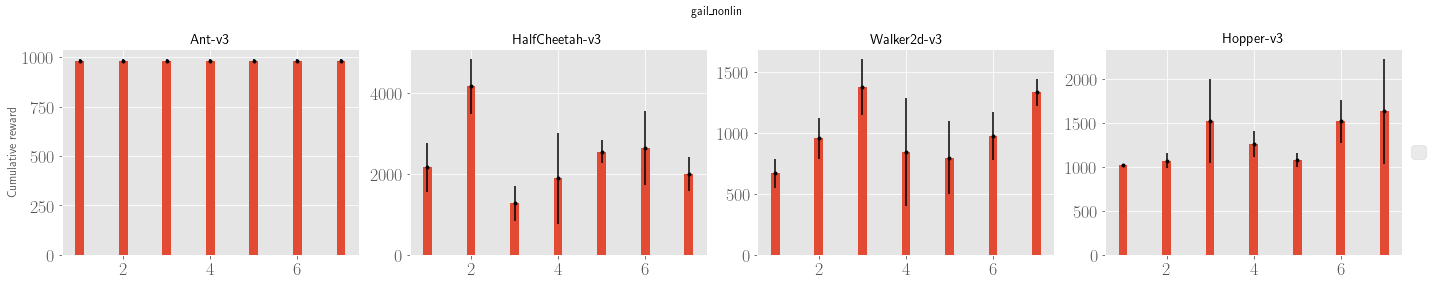

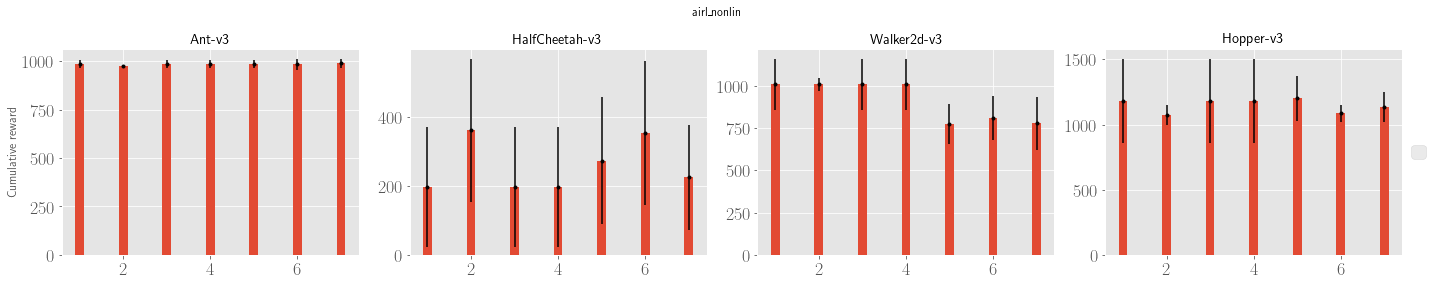

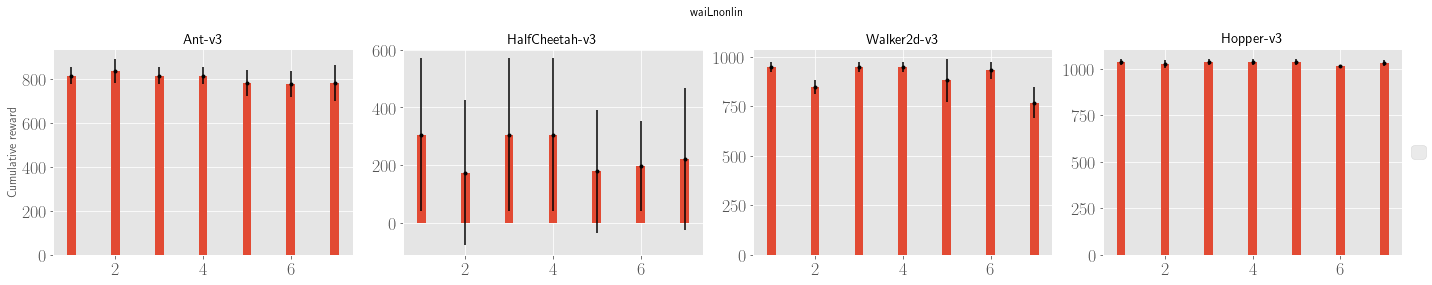

In [29]:
df_dict_ciil = d
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''

X = ['gail', 'airl', 'wail']
ec = [0.0]

for algo in X:
    for ec_ in ec:
        for nob in usenobs:
            for nonlin in disc_nonlins:
                fig, axs = plt.subplots(1,4, figsize=(20,4))
                fig.subplots_adjust(top=0.88)
                fig.suptitle(f"{algo}_{nonlin}")
                plt.style.use('ggplot')
                #print(lin, nob, nonlin)
                #plt.title(lin + nob + nonlin)

                for i, env in enumerate(['Ant-v3', 'HalfCheetah-v3', 'Walker2d-v3', 'Hopper-v3']):

                    X_axis = np.arange(len(lins))
                    axs[i].set_title(env)
                    Y = []
                    Y_ = []

                    for j,lin in enumerate(lins):
                        val_list = []
                        for seed in [515, 234, 894, 322, 72]:
                            ea = df_dict_ciil[env][seed][f"ec_{ec_}"][f"nd_{10}"][lin][nob][nonlin][algo]
                            if not isinstance(ea,dict): # prevents case if we have empty dict
                                df = create_df_from_ea(ea, tags[-1])
                                val_list.append(np.max(df['Value']))
                        
                        if len(val_list) > 0:
                            Y.append(np.mean(val_list))
                            Y_.append(np.std(val_list))
                        else:
                            Y.append(0)            
                            Y_.append(0)

                        #print(Y, Y_)

                    axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2) 
                    axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

                axs[0].set_ylabel("Cumulative reward")
                axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))

                #plt.legend()
                plt.tight_layout()

In [86]:
### cum.rew. plots

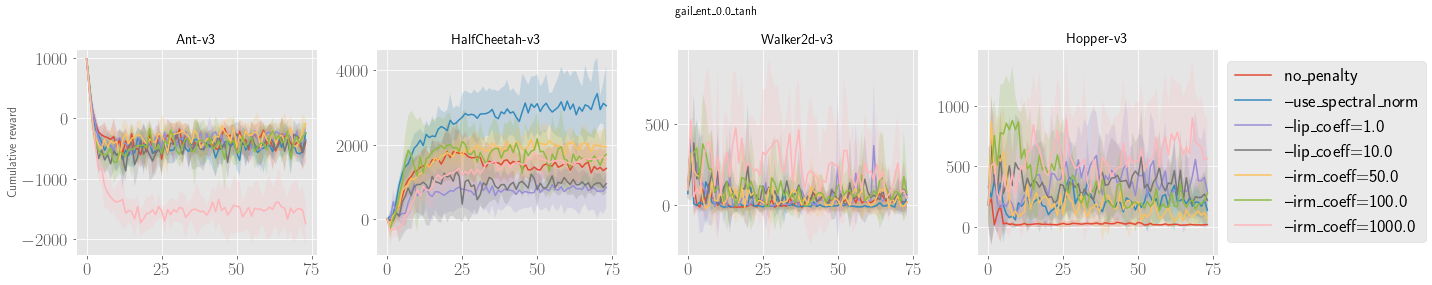

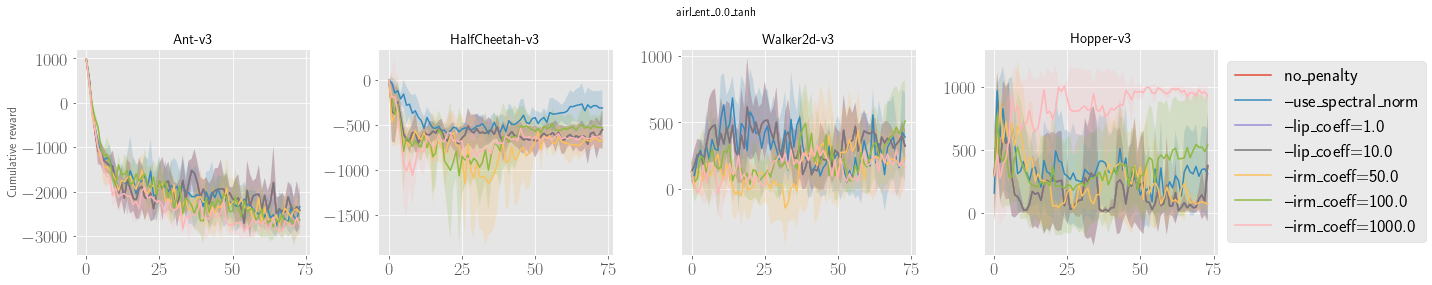

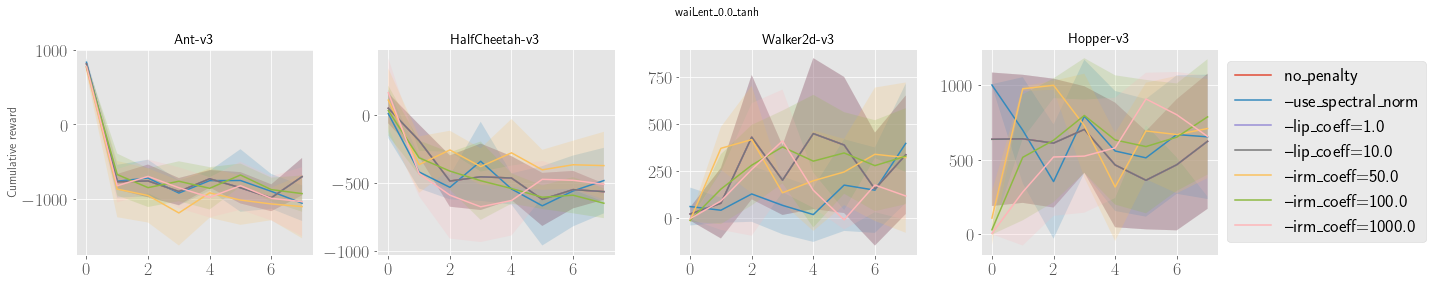

In [26]:
df_dict_ciil = d
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''

X = ['gail', 'airl', 'wail']
ec = [0.0]
subsample = 20

for algo in X:
    for ec_ in ec:
        for nob in usenobs:
            for nonlin in disc_nonlins:
                fig, axs = plt.subplots(1,4, figsize=(20,4))
                fig.subplots_adjust(top=0.88)
                fig.suptitle(f"{algo}_ent_{ec_}_{nonlin}")
                plt.style.use('ggplot')
                #print(lin, nob, nonlin)
                #plt.title(lin + nob + nonlin)

                for i, env in enumerate(['Ant-v3', 'HalfCheetah-v3', 'Walker2d-v3', 'Hopper-v3']):

                    X_axis = np.arange(len(lins))
                    axs[i].set_title(env)
                    Y = []
                    Y_ = []

                    for j,lin in enumerate(lins):
                        val_list = []
                        for seed in [515, 234, 894, 322, 72]:
                            ea = df_dict_ciil[env][seed][f"ec_{ec_}"][f"nd_{10}"][lin][nob][nonlin][algo]
                            if not isinstance(ea,dict): # prevents case if we have empty dict
                                df = create_df_from_ea(ea, tags[-1])
                                val_list.append(df['Value'])

                        if len(val_list) > 0:
                            vals = np.array(val_list)
                            mu = np.mean(vals,0)[::subsample]
                            std = np.std(vals,0)[::subsample]
                            if lin == '':
                                lin_label = 'no_penalty'
                            else:
                                lin_label = lin
                            axs[i].plot(mu, label=lin_label)
                            axs[i].fill_between(np.arange(len(mu)),mu+std, mu-std, alpha=0.2)

                        else:
                            Y.append(0)            
                            Y_.append(0)

                        #print(Y, Y_)

                    #axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2) 
                    #axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

                axs[0].set_ylabel("Cumulative reward")
                axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))

                #plt.legend()
                plt.tight_layout()

In [8]:
def init_results_dict():
    def init_ndemos_dict():
        return {1:{'tanh': {}, 'relu': {}, 'prelu': {}}, 4: {'tanh': {}, 'relu': {}, 'prelu': {}}, 10: {'tanh': {}, 'relu': {}, 'prelu': {}}, 25: {'tanh': {}, 'relu': {}, 'prelu': {}}}
    d = {'Ant-v3': {0.0: init_ndemos_dict(), 0.01:init_ndemos_dict(), 0.1: init_ndemos_dict(), 1.0: init_ndemos_dict(), 10.0: init_ndemos_dict(), 50.0: init_ndemos_dict(), 100.0:init_ndemos_dict()},
            'HalfCheetah-v3': {0.0: init_ndemos_dict(), 0.01:init_ndemos_dict(), 0.1: init_ndemos_dict(), 1.0: init_ndemos_dict(), 10.0: init_ndemos_dict(), 50.0: init_ndemos_dict(), 100.0:init_ndemos_dict()},
                  'Hopper-v3': {0.0: init_ndemos_dict(), 0.01:init_ndemos_dict(), 0.1: init_ndemos_dict(), 1.0: init_ndemos_dict(), 10.0: init_ndemos_dict(), 50.0: init_ndemos_dict(), 100.0:init_ndemos_dict()},
                  'Walker2d-v3': {0.0: init_ndemos_dict(), 0.01:init_ndemos_dict(), 0.1: init_ndemos_dict(), 1.0: init_ndemos_dict(), 10.0: init_ndemos_dict(), 50.0: init_ndemos_dict(), 100.0:init_ndemos_dict()}}
    
    return d

def init_results_dict_small():
    d = {'Ant-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'HalfCheetah-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'Hopper-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'Walker2d-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}}}
    
    return d

def init_results_dict_swil():
    def init_ndemos_dict():
        return {1:{'tanh': {}, 'relu': {}, 'prelu': {}}, 4: {'tanh': {}, 'relu': {}, 'prelu': {}}, 10: {'tanh': {}, 'relu': {}, 'prelu': {}}, 25: {'tanh': {}, 'relu': {}, 'prelu': {}}}
    d = {'Ant-v3': {1:init_ndemos_dict(),5:init_ndemos_dict(),20:init_ndemos_dict(),50:init_ndemos_dict()},
                  'HalfCheetah-v3': {1:init_ndemos_dict(),5:init_ndemos_dict(),20:init_ndemos_dict(),50:init_ndemos_dict()},
                  'Hopper-v3':{1:init_ndemos_dict(),5:init_ndemos_dict(),20:init_ndemos_dict(),50:init_ndemos_dict()},
                  'Walker2d-v3': {1:init_ndemos_dict(),5:init_ndemos_dict(),20:init_ndemos_dict(),50:init_ndemos_dict()}}
    
    return d


In [10]:
def get_dicts_from_ea_swil(ea_dict):
    def parse_fname_swil(fname):    
        intgr = re.findall(r'\d+', fname)
        floats = re.findall(r"\d+\.\d+", fname)
        name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)
        
        m = re.search('seed_(\d+)', fname, re.IGNORECASE)
        seed = int(m.group(1))
        m = re.search('np(\d+)', fname, re.IGNORECASE)
        np = int(m.group(1))

        offset = 0
        if "Walker2d" in fname:
            offset = 1
        #seed = intgr[5+offset]
        n_epc = intgr[-1]
        n_epi = intgr[-2]
        #np = intgr[6+offset]

        #print(fname)
        #print(name)
        #print(seed)
        #print(intgr)

        if len(floats) > 0:
            irm_coeff = floats[0]
        else:
            irm_coeff = 0

        return int(seed), int(np), name
    
    df_dict = {}

    df_dict['sac'] = init_results_dict_swil()
    df_dict['ppo'] = init_results_dict_swil()

    df_dict_flat = {}
    df_dict_max = {}
    irm_coeffs = [0.0, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]

    df_dict_max['sac'] = init_results_dict_swil()
    df_dict_max['ppo'] = init_results_dict_swil()

    hp_dict = {}
    hp_dict['sac'] = init_results_dict_swil()
    hp_dict['ppo'] = init_results_dict_swil()

    for k,v in ea_dict.items():
        seed, irm, name = parse_fname_swil(str(k))
        name = name[0]+'3'

        try:
            df = create_df_from_ea(v, "charts/episodic_return")    
            hparams = get_hparams_from_ea(v)

            n_demos = int(hparams['n_demos'])
            disc_nonlin = hparams['disc_nonlin']

            if 'sac' in str(k):
                df_dict['sac'][name][irm][n_demos][disc_nonlin][seed] = df 
                df_dict_max['sac'][name][irm][n_demos][disc_nonlin][seed] = max(df["Value"])
                hp_dict['sac'][name][irm][n_demos][disc_nonlin][seed] = hparams

            if 'ppo' in str(k):
                df_dict['ppo'][name][irm][n_demos][disc_nonlin][seed] = df 
                #print(k, max(df["Value"]))
                df_dict_max['ppo'][name][irm][n_demos][disc_nonlin][seed] = max(df["Value"])
                hp_dict['ppo'][name][irm][n_demos][disc_nonlin][seed] = hparams

            if 'sac' in str(k):
                df_dict_flat[f"sac_{name}_{irm}_seed{seed}"] = df 
            if 'ppo' in str(k):
                df_dict_flat[f"ppo_{name}_{irm}_seed{seed}"] = df
        except Exception as e: 
            print(e, k)
            pass
        
    return df_dict, df_dict_max, hp_dict

def get_dicts_from_ea(ea_dict, limit_length=-1):
    def parse_fname_il(fname):    
        intgr = re.findall(r'\d+', fname)
        floats = re.findall(r"\d+\.\d+", fname)
        name = re.findall(r"[a-zA-Z0-9]*-[-a-zA-Z0-9]", fname)

        m = re.search('seed_(\d+)', fname, re.IGNORECASE)
        seed = int(m.group(1))
        m = re.search('irm(\d+)', fname, re.IGNORECASE)
        irm = int(m.group(1))

        if len(floats) > 0:
            irm_coeff = floats[0]
        else:
            irm_coeff = 0
        
        return int(seed), float(irm_coeff), name

    df_dict = {}

    df_dict['sac'] = init_results_dict()
    df_dict['ppo'] = init_results_dict()

    df_dict_flat = {}
    df_dict_max = {}
    irm_coeffs = [0.0, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]

    df_dict_max['sac'] = init_results_dict()
    df_dict_max['ppo'] = init_results_dict()

    hp_dict = {}
    hp_dict['sac'] = init_results_dict()
    hp_dict['ppo'] = init_results_dict()

    for k,v in ea_dict.items():
        seed, irm, name = parse_fname_il(str(k))
        name = name[0]+'3'
        df = create_df_from_ea(v, "charts/episodic_return")
        hparams = get_hparams_from_ea(v)

        n_demos = int(hparams['n_demos'])
        disc_nonlin = hparams['disc_nonlin']

        if 'sac' in str(k):
            df_dict['sac'][name][irm][n_demos][disc_nonlin][seed] = df 
            df_dict_max['sac'][name][irm][n_demos][disc_nonlin][seed] = max(df["Value"][:limit_length])
            hp_dict['sac'][name][irm][n_demos][disc_nonlin][seed] = hparams

        if 'ppo' in str(k):
            df_dict['ppo'][name][irm][n_demos][disc_nonlin][seed] = df 
            #print(k, max(df["Value"]))
            df_dict_max['ppo'][name][irm][n_demos][disc_nonlin][seed] = max(df["Value"][:limit_length])
            hp_dict['ppo'][name][irm][n_demos][disc_nonlin][seed] = hparams

        if 'sac' in str(k):
            df_dict_flat[f"sac_{name}_{irm}_seed{seed}"] = df 
        if 'ppo' in str(k):
            df_dict_flat[f"ppo_{name}_{irm}_seed{seed}"] = df

    # add mean and std columns:
    for k,v in ea_dict.items():
        seed, irm, name = parse_fname(str(k))
        name = name[0]+'3'

        if 'sac' in str(k):
            df_dict_max['sac'][name][irm][n_demos][disc_nonlin]['mean']= np.mean(list(df_dict_max['sac'][name][irm][n_demos][disc_nonlin].values()))
            df_dict_max['sac'][name][irm][n_demos][disc_nonlin]['std'] = np.std(list(df_dict_max['sac'][name][irm][n_demos][disc_nonlin].values()))
        if 'ppo' in str(k):
            df_dict_max['ppo'][name][irm][n_demos][disc_nonlin]['mean'] = np.mean(list(df_dict_max['ppo'][name][irm][n_demos][disc_nonlin].values()))
            df_dict_max['ppo'][name][irm][n_demos][disc_nonlin]['std'] = np.std(list(df_dict_max['ppo'][name][irm][n_demos][disc_nonlin].values()))
        
    #for algo in ['sac', 'ppo']
    #    for task in ['Ant-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Walker2d-v3']:
    return df_dict, df_dict_max, hp_dict

In [9]:
df_dict_swil = get_dicts_from_ea_swil(ea_dict_swil)
df_dict_airl = get_dicts_from_ea(ea_dict_airl, limit_length=1000)
df_dict_gail = get_dicts_from_ea(ea_dict_gail, limit_length=1000)

/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/iov/.miniforge3/envs/mldev/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


In [157]:
#print(json.dumps(df_dict_gail[1]['ppo']['Hopper-v3'][0.0][10]["tanh"], indent=4))
#print(json.dumps(df_dict_swil[1]['ppo']['Hopper-v3'], indent=4))
import json
print(json.dumps(df_dict_swil[1]['ppo']['Walker2d-v3'], indent=4))

NameError: name 'df_dict_swil' is not defined

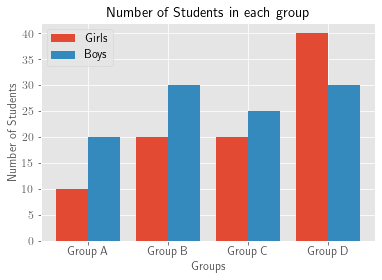

In [107]:
X = ['Group A','Group B','Group C','Group D']
Ygirls = [10,20,20,40]
Zboys = [20,30,25,30]
  
X_axis = np.arange(len(X))
  
plt.bar(X_axis - 0.2, Ygirls, 0.4, label = 'Girls')
plt.bar(X_axis + 0.2, Zboys, 0.4, label = 'Boys')
  
plt.xticks(X_axis, X)
plt.xlabel("Groups")
plt.ylabel("Number of Students")
plt.title("Number of Students in each group")
plt.legend()
plt.show()

In [ ]:
df_dict_airl[1]['ppo']['Hopper-v3'][50][25]['prelu']

In [158]:
df_dict_swil[1]['ppo']['Hopper-v3'][50][25]['prelu']

NameError: name 'df_dict_swil' is not defined

In [16]:
df_dict_swil[1]['ppo']['Hopper-v3'][50][25]['relu']

{72: 927.7400512695312,
 515: 3406.425537109375,
 894: 1654.19775390625,
 322: 926.4964599609375,
 234: 3226.705078125}

['gail', 'airl', 'swil:np1', 'swil:np5', 'swil:np20', 'swil:np50']
[2653.2724609375, 1182.0343017578125, -155.1981231689453, -206.96801147460937, 300.8259521484375, -13.546890258789062] [14.14697265625, 645.9378662109375, 147.40064943005467, 26.987997570341026, 436.84062825792586, 230.66837014989386]
[-291.09600830078125, 1393.4683837890625, -156.9907901763916, -95.90299377441406, 71.93595962524414, -66.62425231933594] [0.0, 812.4410400390625, 100.50663424234028, 122.61603157048036, 263.4503286323058, 304.49641827814634]
[905.0593719482422, 687.9981079101562, -209.75018615722655, -126.37853317260742, -194.68915557861328, 48.00048828125] [470.0855922387482, 498.5667790796643, 61.25584707959414, 78.67367558278232, 78.5753692878288, 238.79537862896524]
['gail', 'airl', 'swil:np1', 'swil:np5', 'swil:np20', 'swil:np50']
[2855.38671875, 20.076002438863117, 604.1818214416504, 1483.20390625, 985.8616943359375, 1176.28525390625] [769.50439453125, 10.705931384703979, 361.15055611444376, 641.4755

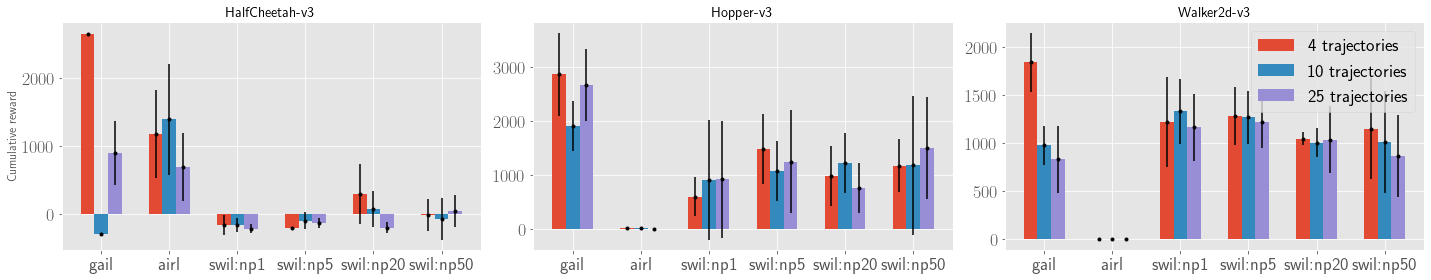

In [13]:
fig, axs = plt.subplots(1,3, figsize=(20,4))
nonlin="prelu"
plt.style.use('ggplot')

for i, env in enumerate(['HalfCheetah-v3', 'Hopper-v3', 'Walker2d-v3']):
    X = ['gail','airl','swil:np1','swil:np5','swil:np20','swil:np50']
    X_axis = np.arange(len(X))

    axs[i].set_title(env)
    #plt.gca()
    #plt.xticks(X_axis, X)
    print(X)
    axs[i].set_xticks(X_axis,X)

    for j,nd in enumerate([4,10,25]):
        Y = []
        Y_ = []
        gail_val = list(df_dict_gail[1]['ppo'][env][0.0][nd][nonlin].values())
        airl_val = list(df_dict_airl[1]['ppo'][env][0.0][nd][nonlin].values())
        if len(gail_val) > 0:
            Y.append(np.mean(gail_val))
            Y_.append(np.std(gail_val))
        else:
            Y.append(0)
            Y_.append(0)
        
        if len(airl_val) > 0:
            Y.append(np.mean(airl_val))
            Y_.append(np.std(airl_val))
        else:
            Y.append(0)
            Y_.append(0)

        n_proj = [1,5,20,50]
        for n_p in n_proj:
            swil_val = list(df_dict_swil[1]['ppo'][env][n_p][nd][nonlin].values())
            if len(swil_val) > 0:
                Y.append(np.mean(swil_val))
                Y_.append(np.std(swil_val))
            else:
                Y.append(0)            
                Y_.append(0)
                
        print(Y, Y_)
                
        axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2, label=f"{nd} trajectories") 
        axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 

        #plt.gca()
        #plt.xticks(X_axis, X)

axs[0].set_ylabel("Cumulative reward")

plt.legend()
plt.tight_layout()
plt.savefig(f"il_bar_ae_{nonlin}.png")

AttributeError: 'int' object has no attribute 'arange'

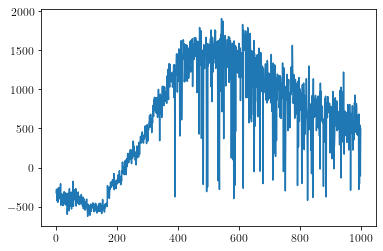

In [83]:
plt.plot(df_dict_swil[0]['ppo']['HalfCheetah-v3'][50][4]["relu"][515].Value)

In [ ]:
# TODO: filter length!!

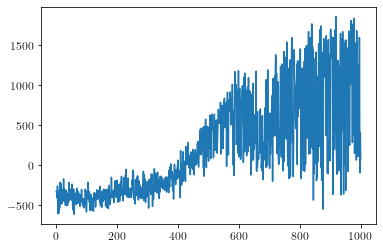

In [70]:
plt.plot(df_dict_gail[0]['ppo']['HalfCheetah-v3'][0.0][4]["relu"][234].Value[:1000])

5996


In [114]:
hp_dict['ppo']['Hopper-v3'][0.0][322]['disc_nonlin']

'relu'

In [ ]:
for d_nl in ['tanh', 'relu', 'prelu']:
    fig, axs = plt.subplots(4,3)
    for i, env in enumerate(df_dict['ppo'].keys()):
        for j, n_d in [4,10,25]:
            df_dict['ppo'][env][irm][n_demos][d_nl][seed]
            axs[i,j].set_title(f"{env}_nd:{n_d}")
            axs[i,j].plot(

        

In [155]:
for k,v in df_dict['ppo']['Walker2d-v3'][50.0][10]['prelu'].items():
    print(k, v)
    
    


515              Time     Step     Value
0        0.000000     1500 -0.764883
1       23.142910    15000 -5.689853
2       27.010423    17500 -2.968529
3       29.962467    19000 -5.054384
4       30.937723    20000 -3.482851
...           ...      ...       ...
1746  4290.505352  2559000 -7.436196
1747  4311.053514  2571500 -7.268868
1748  4317.714852  2575500 -7.428249
1749  4323.877058  2579000 -7.643921
1750  4327.684705  2581500 -7.198045

[1751 rows x 3 columns]
322             Time     Step       Value
0       0.000000    14000   -5.001307
1       3.001877    15500   -2.907154
2       5.493484    16500   -1.048481
3       9.560389    19000   -3.378974
4      17.495736    24000   -4.126066
..           ...      ...         ...
134  3594.761096  2181500  289.277252
135  3927.594529  2379000  281.316620
136  3937.228525  2384500  285.799683
137  4027.196617  2439000  335.873840
138  4519.031038  2734000  124.972641

[139 rows x 3 columns]
894              Time     Step     Value
0 

In [ ]:
res_gail_df = pd.DataFrame.from_dict({(i,j, k): df_dict_max[i][j][k] 
                           for i in df_dict_max.keys() 
                           for j in df_dict_max[i].keys()
                           for k in df_dict_max[i][j].keys()},
                       orient='index')

In [ ]:
res_gail_df.to_pickle("results_gail_df.pkl")

## GAIL

In [5]:
pd.read_pickle('runs/results_gail_df.pkl')

894          515          322           72  \
sac Ant-v3         0.00     676.376221   700.574524  4913.348145  4815.951660   
                   0.01     623.839233   541.321350  5033.834473  4663.919922   
                   0.10    3940.081787    45.325104   638.056274   736.916870   
                   1.00    4685.344238   595.598877   752.271790  4866.985840   
                   10.00   4992.723633  4868.615234  5045.855469  4910.984863   
                   50.00   5220.516602  4727.837402  4759.119141   664.192566   
                   100.00  5085.586914  4879.076660  4868.798340  4972.281250   
    HalfCheetah-v3 0.00    1050.050171   605.405579   783.187195  1170.237427   
                   0.01    1240.304810   460.127350  1957.177979  1014.228516   
                   0.10    2364.046143   -28.192930  2692.815674  2686.982666   
                   1.00     830.781799   527.443237   520.319275  1401.793823   
                   10.00    873.690491  -137.693787  2981.153809  1099.637939   
                   50.00   2743.581055   905.268921  1769.093628  2477.389160   
                   100.00  2607.611572  3355.988281  2508.570557  2252.916504   
    Hopper-v3      0.00    3751.871582  2619.705078  3824.930420  3750.738525   
                   0.01    3816.654053  1070.172119  3735.301270  3742.739258   
                   0.10    3782.879150  1096.039062  3758.923828  3810.765137   
                   1.00    3740.716553  1252.370972  3783.882568  3782.196533   
                   10.00   3782.674072   726.752197  3822.311279  3777.184570   
                   50.00   3847.760010  3729.270020  3731.682373  3777.490479   
                   100.00  3793.881348  3771.494141  3767.430420  3757.893311   
    Walker2d-v3    0.00    4209.707520  4205.192383  4202.840332  4256.743652   
                   0.01    4202.746582   813.704285  4272.361328  4200.216797   
                   0.10    4204.113281  1019.107117  4239.318848  4274.334961   
                   1.00    4365.065430  1220.491821  4192.954590  4199.104492   
                   10.00   4164.021973  4144.807617  4221.058594  4156.474609   
                   50.00   4205.699707  4194.705566  4168.098633  4203.696289   
                   100.00  4180.796875  4228.318848  4247.885742  4238.807617   
ppo Ant-v3         0.00      11.473398    36.075840    37.506504    10.549633   
                   0.01      40.443623    18.222864    25.369833    14.739595   
                   0.10      27.039841    29.548943    32.517773    27.267149   
                   1.00      10.961298     6.518288     8.100368    15.688511   
                   10.00     34.317764    12.699681    22.452826    21.807932   
                   50.00     10.164933    49.092613    16.645578     1.591449   
                   100.00    25.531754    30.352652    70.614151     5.799210   
    HalfCheetah-v3 0.00    3798.295898  3586.949219  3196.976562  3584.951660   
                   0.01    3666.728760   341.467499  3167.762695  3233.200684   
                   0.10    3980.781494   360.360901  3183.169434  3786.373535   
                   1.00    3447.347168  1193.182373  2679.071533  2962.717285   
                   10.00   3940.368164  3479.629150  2516.805908  3932.761475   
                   50.00   2978.345459   925.008789   397.280121  2696.821045   
                   100.00  1848.131226   432.102173   102.776169  1313.062256   
    Hopper-v3      0.00    3719.272949  3781.570557  3749.106689  3591.705078   
                   0.01    3633.799561  2512.307617  3798.491455  3559.070557   
                   0.10    3831.079102  2397.017334  3755.323975  3685.725342   
                   1.00    3661.656982  3753.000244  3760.584473  3348.490967   
                   10.00   3483.358398  2582.780518  3599.912598  3381.552734   
                   50.00   3554.379395  3608.683350  3098.077637  3362.065430   
                   100.00  3365.095459  3451.179688  2698.225342  

## AIRL

In [7]:
df_airl = pd.read_pickle('runs/results_airl_df.pkl')

In [15]:
df_airl.keys()

Int64Index([234, 72, 894, 515, 322], dtype='int64')

In [59]:
df_airl_flat = df_airl.reset_index()

In [73]:
df_airl['std'] = np.std(df_airl[[234, 72, 894, 515, 322]].to_numpy(),axis=-1)

In [74]:
df_airl

234           72          894          515  \
sac Ant-v3         0.00     483.291931    59.400978   604.213379   139.424469   
                   0.01     403.783112   205.402786   459.946930   370.916626   
                   0.10     551.864197   104.478088   474.341217   165.403152   
                   1.00     330.916412   406.610748   505.360718   319.577820   
                   10.00    249.304428   134.562592   623.141418    56.282761   
                   50.00   4015.996582   576.267212  5220.516602    13.729894   
                   100.00  4654.313477  4972.281250    28.310596    13.729894   
    HalfCheetah-v3 0.00    2071.021240  2046.219360  2820.336182  3176.860352   
                   0.01    2148.427246  2290.396240  2757.764404  5198.082520   
                   0.10    2024.903198  1957.752808  4805.777344  1688.068726   
                   1.00    1684.321777  2059.267578  2919.491211  2326.004639   
                   10.00   2751.894043  2329.150146  3019.638916  3046.399170   
                   50.00   2243.714111  2477.389160  2743.581055  6249.576172   
                   100.00  2646.953613  2252.916504  5420.436035  4616.190430   
    Hopper-v3      0.00    3626.355713  3553.887695  3536.931152  3630.415039   
                   0.01    3474.078369  3600.796875  3595.609375  3599.485352   
                   0.10    3240.600342  3592.527100  3609.083984  3377.240967   
                   1.00    3099.529297  3636.947510  3631.552002  3527.853027   
                   10.00   1865.920410  3353.731934   693.715149  3194.821777   
                   50.00   3765.761230  3777.490479  3847.760010  3801.107666   
                   100.00  3808.569580  3757.893311  3718.707031  3657.572998   
    Walker2d-v3    0.00    2236.457764  3030.392822  3058.033203  2136.412598   
                   0.01    1081.258179  1989.995239  1645.831665  3719.665283   
                   0.10    1224.322144  3094.415039  1999.993530  2321.649170   
                   1.00    1656.479980  3492.246094  1342.818359  1358.179077   
                   10.00   1891.841675  1763.655029  2162.526367  2302.137939   
                   50.00   4221.286621  4164.283203  4205.699707  4156.162109   
                   100.00  4223.771973  4238.807617  4003.868896  4183.549316   
ppo Ant-v3         0.00      46.790371    46.989922    56.378918    60.252716   
                   0.01      50.076881    68.271469    74.885323    60.917244   
                   0.10     106.275482    84.975510    39.713268    77.713623   
                   1.00      74.789452    41.421638    51.339752    80.600304   
                   10.00     48.642921    50.275761    62.416676    44.522511   
                   50.00     63.140957    61.208462    10.164933    44.897614   
                   100.00     5.388231     5.799210    56.344330    41.834270   
    HalfCheetah-v3 0.00     480.886963   324.844604   380.534302   793.647827   
                   0.01     326.130981   114.595215   378.616608     7.771274   
                   0.10     144.437958   191.816666   348.630402   356.241119   
                   1.00     356.353027   511.478424   361.745697   955.655823   
                   10.00    305.095428    10.646875    -2.630314    80.701683   
                   50.00   2272.612061   -59.990936  2978.345459  -159.431595   
                   100.00   254.273987  1313.062256  -171.994888  -220.191635   
    Hopper-v3      0.00     125.196632   110.376816   143.280212   200.400864   
                   0.01     125.196632   110.376816   135.511261   200.400864   
                   0.10     125.196632   110.376816   135.511261   200.400864   
                   1.00     125.196632   115.745094   135.511261   200.400864   
                   10.00    125.196632   122.076004   135.511261   200.400864   
                   50.00    125.196632   110.376816  3554.379395   200.400864   
                   100.00  3330.606689  3242.875732   135.511261  

In [41]:
df_airl_flat.columns = ['algo', 'env', 'irm_c', 234, 72, 894, 515, 322]

In [13]:
tags = ["charts/episodic_return", "irl/gail_bce_loss"]
run_dir = Path("runs/airl_folders")      
#df_dict = load_dirs(run_dir, tags)

In [14]:
dlist = []

for d in run_dir.iterdir():
    if 'max.pkl' in str(d):
        dlist.append(pkl.load(open(d,'rb')))

In [16]:
from functools import reduce

def merge(a, b, path=None):
    "merges b into a"
    if path is None: path = []
    for key in b:
        if key in a:
            if isinstance(a[key], dict) and isinstance(b[key], dict):
                merge(a[key], b[key], path + [str(key)])
            elif a[key] == b[key]:
                pass # same leaf value
            else:
                raise Exception('Conflict at %s' % '.'.join(path + [str(key)]))
        else:
            a[key] = b[key]
    return a

def combine_into(d: dict, combined: dict) -> None:
    for k, v in d.items():
        if isinstance(v, dict):
            combine_into(v, combined.setdefault(k, {}))
        else:
            combined[k] = v



In [17]:
d_all = {}
for d in dlist:
    combine_into(d, d_all)


In [19]:
res_airl_df =pd.DataFrame.from_dict({(i,j, k): d_all[i][j][k] 
                           for i in d_all.keys() 
                           for j in d_all[i].keys()
                           for k in d_all[i][j].keys()},
                       orient='index')

In [21]:
res_airl_df

234          72           894          515  \
sac Ant-v3         0.00     483.291931    59.400978   604.213379   139.424469   
                   0.01     403.783112   205.402786   459.946930   370.916626   
                   0.10     551.864197   104.478088   474.341217   165.403152   
                   1.00     330.916412   406.610748   505.360718   319.577820   
                   10.00    249.304428   134.562592   623.141418    56.282761   
                   50.00   4015.996582   576.267212  5220.516602    13.729894   
                   100.00  4654.313477  4972.281250    28.310596    13.729894   
    HalfCheetah-v3 0.00    2071.021240  2046.219360  2820.336182  3176.860352   
                   0.01    2148.427246  2290.396240  2757.764404  5198.082520   
                   0.10    2024.903198  1957.752808  4805.777344  1688.068726   
                   1.00    1684.321777  2059.267578  2919.491211  2326.004639   
                   10.00   2751.894043  2329.150146  3019.638916  3046.399170   
                   50.00   2243.714111  2477.389160  2743.581055  6249.576172   
                   100.00  2646.953613  2252.916504  5420.436035  4616.190430   
    Hopper-v3      0.00    3626.355713  3553.887695  3536.931152  3630.415039   
                   0.01    3474.078369  3600.796875  3595.609375  3599.485352   
                   0.10    3240.600342  3592.527100  3609.083984  3377.240967   
                   1.00    3099.529297  3636.947510  3631.552002  3527.853027   
                   10.00   1865.920410  3353.731934   693.715149  3194.821777   
                   50.00   3765.761230  3777.490479  3847.760010  3801.107666   
                   100.00  3808.569580  3757.893311  3718.707031  3657.572998   
    Walker2d-v3    0.00    2236.457764  3030.392822  3058.033203  2136.412598   
                   0.01    1081.258179  1989.995239  1645.831665  3719.665283   
                   0.10    1224.322144  3094.415039  1999.993530  2321.649170   
                   1.00    1656.479980  3492.246094  1342.818359  1358.179077   
                   10.00   1891.841675  1763.655029  2162.526367  2302.137939   
                   50.00   4221.286621  4164.283203  4205.699707  4156.162109   
                   100.00  4223.771973  4238.807617  4003.868896  4183.549316   
ppo Ant-v3         0.00      46.790371    46.989922    56.378918    60.252716   
                   0.01      50.076881    68.271469    74.885323    60.917244   
                   0.10     106.275482    84.975510    39.713268    77.713623   
                   1.00      74.789452    41.421638    51.339752    80.600304   
                   10.00     48.642921    50.275761    62.416676    44.522511   
                   50.00     63.140957    61.208462    10.164933    44.897614   
                   100.00     5.388231     5.799210    56.344330    41.834270   
    HalfCheetah-v3 0.00     480.886963   324.844604   380.534302   793.647827   
                   0.01     326.130981   114.595215   378.616608     7.771274   
                   0.10     144.437958   191.816666   348.630402   356.241119   
                   1.00     356.353027   511.478424   361.745697   955.655823   
                   10.00    305.095428    10.646875    -2.630314    80.701683   
                   50.00   2272.612061   -59.990936  2978.345459  -159.431595   
                   100.00   254.273987  1313.062256  -171.994888  -220.191635   
    Hopper-v3      0.00     125.196632   110.376816   143.280212   200.400864   
                   0.01     125.196632   110.376816   135.511261   200.400864   
                   0.10     125.196632   110.376816   135.511261   200.400864   
                   1.00     125.196632   115.745094   135.511261   200.400864   
                   10.00    125.196632   122.076004   135.511261   200.400864   
                   50.00    125.196632   110.376816  3554.379395   200.400864   
                   100.00  3330.606689  3242.875732   135.511261  

In [20]:
res_airl_df.to_pickle("results_airl_df.pkl")

In [31]:
dflist = []
for d in dlist:
    df = pd.DataFrame.from_dict({(i,j, k): d[i][j][k] 
                           for i in d.keys() 
                           for j in d[i].keys()
                           for k in d[i][j].keys()},
                       orient='index')
    dflist.append(df)

In [40]:
d = {}
d['sac'] = {'Ant-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'HalfCheetah-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'Hopper-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'Walker2d-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}}}
d['ppo'] = {'Ant-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'HalfCheetah-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'Hopper-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}},
                  'Walker2d-v3': {0.0:{},0.01:{},0.1:{},1.0:{},10.0:{},50.0:{},100.0:{}}}

df_all = pd.DataFrame.from_dict({(i,j, k): d[i][j][k] 
                           for i in d.keys() 
                           for j in d[i].keys()
                           for k in d[i][j].keys()},
                       orient='index')
for df in dflist:
    df_all.join(df)

ValueError: cannot join with no overlapping index names